# Stereo correspondence from a scanned laser stripe

**Goal.** Depth from two hardware-synchronised, rectified EVK4 cameras that watch a line laser swept across the
scene by a stepper motor. Two facts narrow the correspondence search:

* **Shared clock**: at any instant, both cameras see the same physical stripe, so events from the same time window
  belong together.
* **Rectification**: a scene point lies on the same row in both images, so only x has to be matched.

**Methods compared** (ON events only; `stripe_stereo.py`):

| | Method | Idea |
|---|---|---|
| A | window + Hough line | Cut the scan into time windows. In each window, detect the stripe of each camera as a straight line (Hough transform, then a least-squares fit on its inliers). Disparity per row = x_L(y) − x_R(y). |
| A′ | A, motion-compensated | As A, but each event is first moved to where the stripe was at the window centre: x − v·(t − t_c), with v the scan speed. |
| B | window + row median | Same windows. Per row, the stripe position is the median x of that row's events. Disparity = median_L − median_R. |
| B′ | B, motion-compensated | As B, with the same motion compensation. |
| C | per-event time matching | For every left event (x_L, y, t), find where the right stripe was at exactly time t on row y: local linear fit of x_R against t_R over the right events with \|t_R − t\| ≤ τ, rows y ± 1. Disparity = x_L − x_R(t). |

Window lengths and τ are given as **stripe motion in pixels** (16 px windows, τ = ±8 px by default), converted to
µs with each recording's scan speed, so the methods are compared at the same spatial scale for every dwell.

**Data.** `04_dual_cam_recorder/recordings/cw` (filters OFF) and `cw_with_trail_filter`, dwell 10/20/50/100 µs,
continuous-wave laser (no modulation), hardware sync (left = master). Calibration: step 2,
`stereo_00050496_00051788.json` (13 Nov; baseline 50.1 mm, f = 1690 px).

**Ground truth.** None was recorded, but the target turns out to be a flat surface at ~0.57 m (section 4). Every
method is scored against a robust plane fitted to its own 3D points. This measures precision and outliers, not
absolute accuracy. A synthetic object (section 8) tests non-flat scenes against a known answer.

Results are cached in `cache/stripe/`. Set `USE_CACHE = False` to recompute (about 20 minutes).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import stripe_stereo as ss

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
USE_CACHE = True

geom = ss.load_geometry()
OFF, TRAIL = ss.FOLDERS["filters OFF"], ss.FOLDERS["trail filter ON"]
FOLDER_LABEL = {OFF: "filters OFF", TRAIL: "trail filter ON"}
METHODS = list(ss.DEFAULT_PX)
SHORT = {m: m.split(":")[0] for m in METHODS}
M_COLORS = dict(zip(METHODS, ["#9ecae1", "#08519c", "#fdae6b", "#d94801", "#238b45"]))
CAM_COLORS = {"left": "#1f77b4", "right": "#d62728"}

results = {(f, d): ss.evaluate_recording(f, d, geom, use_cache=USE_CACHE) for f in (OFF, TRAIL) for d in ss.DWELLS}
print(f"geometry: f = {geom.f:.1f} px, baseline = {geom.baseline * 1e3:.2f} mm, "
      f"calibration epipolar error = {geom.rect_rms_px:.2f} px RMS")


def grid(row, x, val, cell=4):
    """Median of val per (cell x cell) block of the left rectified image (NaN where empty)."""
    gx, gy = 1280 // cell, 720 // cell
    k = np.clip(np.asarray(row, np.int64) // cell, 0, gy - 1) * gx + np.clip((np.asarray(x) // cell).astype(np.int64), 0, gx - 1)
    kk, med, _ = ss._group_median(k, np.asarray(val, np.float64))
    out = np.full(gx * gy, np.nan)
    out[kk] = med
    return out.reshape(gy, gx)


def md_table(header, rows):
    out = "| " + " | ".join(header) + " |\n|" + "---|" * len(header) + "\n"
    out += "\n".join("| " + " | ".join(str(c) for c in row) + " |" for row in rows)
    display(Markdown(out))

geometry: f = 1689.6 px, baseline = 50.13 mm, calibration epipolar error = 0.75 px RMS


## 1. Data overview

*Scan*: one pass of the stripe across the image; consecutive scans alternate direction. *Cross time*: time for the
stripe to cross the 1280 px width at the measured speed, i.e. the time a full depth frame takes. *First-ON events*:
events kept per scan and camera (first ON event per pixel, after the neighbour filter, see section 2). *Gaps*:
holes in the event stream (lost data).

In [2]:
rows = []
for (f, d), r in results.items():
    s = r["summary"]
    gaps = s["gaps"]
    rows.append([FOLDER_LABEL[f], d, s["n_scans"], f"{s['speed_px_ms']:.1f}", f"{s['cross_ms']:.0f}",
                 f"{1e3 / s['cross_ms']:.0f}", f"{s['first_on']['left'] / 1e3:.0f} / {s['first_on']['right'] / 1e3:.0f}",
                 f"{s['hot_removed']['right'] / max(s['n_raw']['right'], 1) * 100:.0f} %",
                 f"{len(gaps['left'])} / {len(gaps['right'])}"])
md_table(["Filters", "Dwell (µs)", "Scans", "Stripe speed (px/ms)", "Cross time (ms)", "Max fps (one direction)",
          "First-ON events per scan L / R (k)", "Right events removed as hot pixels", "Gaps L / R"], rows)

| Filters | Dwell (µs) | Scans | Stripe speed (px/ms) | Cross time (ms) | Max fps (one direction) | First-ON events per scan L / R (k) | Right events removed as hot pixels | Gaps L / R |
|---|---|---|---|---|---|---|---|---|
| filters OFF | 10 | 7 | 65.0 | 20 | 51 | 163 / 51 | 96 % | 0 / 0 |
| filters OFF | 20 | 5 | 38.0 | 34 | 30 | 447 / 239 | 91 % | 0 / 0 |
| filters OFF | 50 | 7 | 13.7 | 94 | 11 | 704 / 611 | 75 % | 0 / 0 |
| filters OFF | 100 | 7 | 8.5 | 150 | 7 | 706 / 718 | 60 % | 0 / 0 |
| trail filter ON | 10 | 6 | 70.6 | 18 | 55 | 57 / 42 | 0 % | 3 / 0 |
| trail filter ON | 20 | 8 | 72.6 | 18 | 57 | 55 / 46 | 0 % | 2 / 0 |
| trail filter ON | 50 | 6 | 17.2 | 74 | 13 | 314 / 307 | 0 % | 4 / 0 |
| trail filter ON | 100 | 5 | 8.9 | 143 | 7 | 358 / 501 | 0 % | 0 / 0 |

With 10 and 20 µs dwell, the stripe crosses the image in ~13–34 ms, comfortably above 10 fps; 50 µs gives ~90 ms
(just 10 fps) and 100 µs ~150 ms (below). The two hot pixels still dominate the right camera's event count and are
removed. With the trail filter on, the left camera again shows a few gaps in its stream.

Note: the trail-filter "20 µs" recording scans at the same speed as its "10 µs" recording (~72 px/ms, against
38 px/ms for `cw/20us`), so it was probably recorded with a 10 µs dwell. Its results are listed under 20 µs as
labelled.

## 2. What the stripe looks like in the events

One rectified row, one scan: the time of the first ON event of every pixel against its x. The stripe produces a thin,
straight band, and the two cameras' bands are offset by the disparity. The panels on the left take the first ON
event of each pixel as is; the panels on the right apply the **neighbour filter** first (keep an event only if
≥ 2 of the 8 neighbouring pixels fired within ±300 µs).

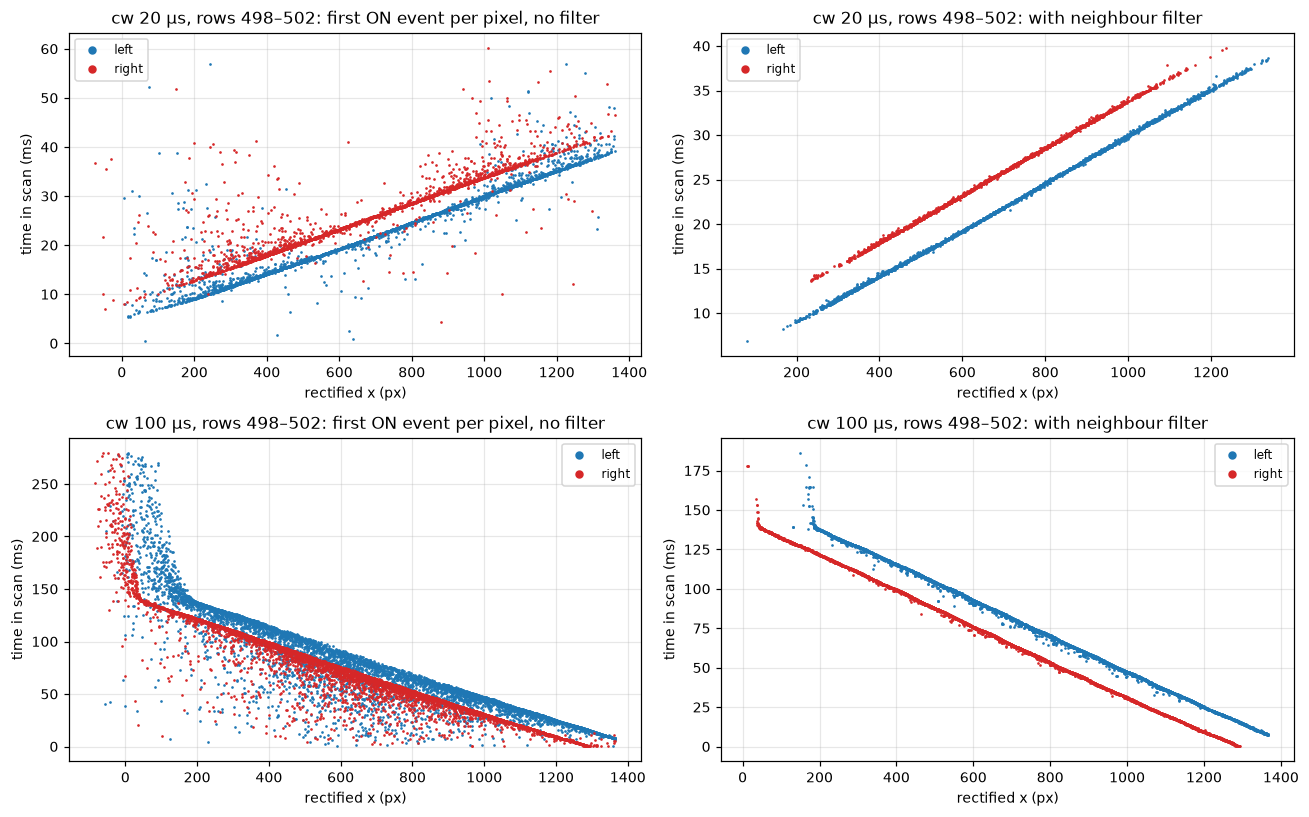

In [3]:
fig, axs = plt.subplots(2, 2, figsize=(12, 7.5))
for i, dw in enumerate((20, 100)):
    p, scans = ss.get_pair(OFF, dw, geom)
    scan = scans[1]
    raw = {}
    for side, st in (("left", p.left), ("right", p.right)):
        i0, i1 = np.searchsorted(st.t, [scan.t0, scan.t1])
        _, first = np.unique(st.pix[i0:i1], return_index=True)
        raw[side] = first + i0
    for j, (label, idx) in enumerate((("first ON event per pixel, no filter", raw), ("with neighbour filter", scan.idx))):
        ax = axs[i, j]
        for side, st in (("left", p.left), ("right", p.right)):
            k = idx[side]
            k = k[(st.row[k] >= 498) & (st.row[k] <= 502)]
            ax.plot(st.xr[k], (st.t[k] - scan.t0) / 1e3, ".", ms=1.5, color=CAM_COLORS[side], label=side)
        ax.set_title(f"cw {dw} µs, rows 498–502: {label}")
        ax.set_xlabel("rectified x (px)"); ax.set_ylabel("time in scan (ms)"); ax.legend(markerscale=6, fontsize=8)
plt.tight_layout(); plt.show()

Without the filter, many pixels fire *before* the stripe arrives, from background activity and scattered laser
light. That is worst for long dwells, where a scan lasts longer. Late events also appear on the right camera.
Because the first event of a pixel is taken as the stripe's arrival, these isolated events replace the true
arrival time. The neighbour filter removes nearly all of them, because the stripe is a continuous line and its
neighbouring pixels fire almost together. Section 7 quantifies its effect.

### One time window, as used by methods A and B

All first-ON events of a 16 px-of-motion window (cw 20 µs: 422 µs), both cameras, raw and motion-compensated, with
the line found by the Hough step.

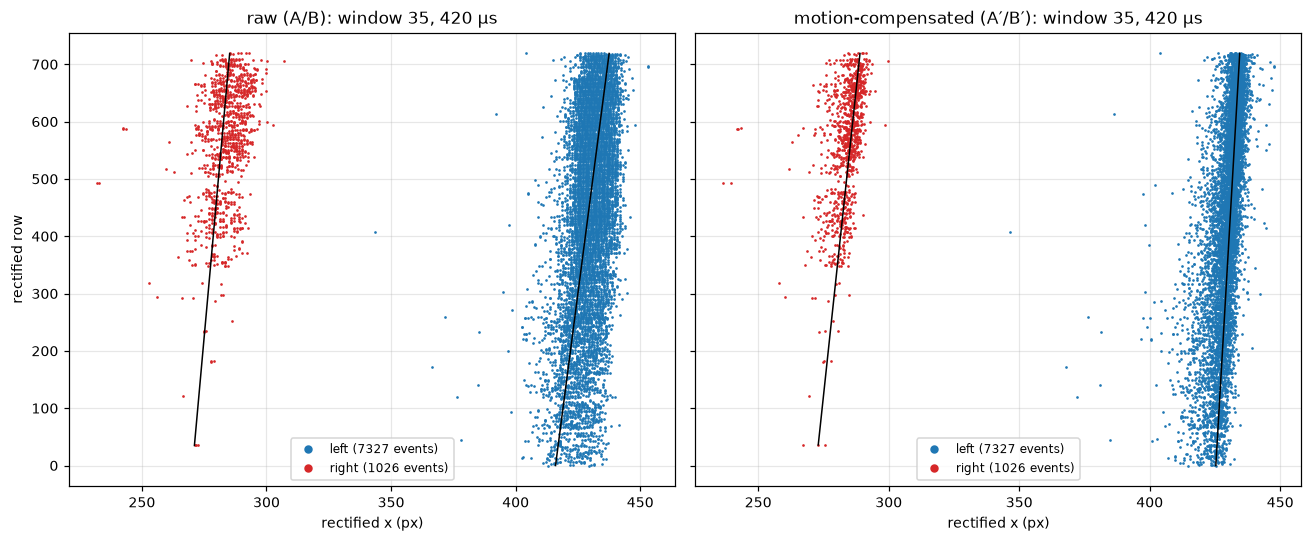

In [4]:
p, scans = ss.get_pair(OFF, 20, geom)
scan = scans[1]
dt = 16 / scan.speed_px_ms * 1e3
w0 = int(15e3 // dt)
fig, axs = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for j, comp in enumerate((False, True)):
    ax = axs[j]
    for side, st in (("left", p.left), ("right", p.right)):
        t, x, row = ss.scan_events(st, scan.idx[side])
        w = ((t - scan.t0) // dt).astype(np.int64)
        if comp:
            x = ss._compensate(x, t, w, scan, dt)
        k = w == w0
        ax.plot(x[k], row[k], ".", ms=1.5, color=CAM_COLORS[side], label=f"{side} ({k.sum()} events)")
        line = ss.hough_line(x[k], row[k].astype(float))
        if line:
            yy = np.array([line[2], line[3]])
            ax.plot(line[0] + line[1] * yy, yy, "k-", lw=1)
    ax.invert_yaxis(); ax.set_xlabel("rectified x (px)"); ax.legend(markerscale=6, fontsize=8)
    ax.set_title(("motion-compensated (A′/B′)" if comp else "raw (A/B)") + f": window {w0}, {dt:.0f} µs")
axs[0].set_ylabel("rectified row")
plt.tight_layout(); plt.show()

In a raw window, the stripe is a band as wide as the motion during the window (16 px). Which part of the band a
line fit or median picks depends on how the events happen to be spread in time, which is different in the two
cameras. Motion compensation collapses the band to the stripe's position at the window centre.

## 3. Precision floor: how precisely a single event marks the stripe

The scatter of single events around their own camera's local stripe fit (rows ± 1, ±8 px of motion), as MAD.

In [5]:
rows = []
for (f, d), r in results.items():
    s = r["summary"]
    rows.append([FOLDER_LABEL[f], d, f"{s['scatter_px']['left']:.2f} / {s['scatter_px']['right']:.2f}",
                 f"{s['scatter_us']['left']:.0f} / {s['scatter_us']['right']:.0f}",
                 f"{s['scatter_px']['left'] * results[(f, d)]['default'][METHODS[1]]['mm_per_px']:.1f}"])
md_table(["Filters", "Dwell (µs)", "Event scatter L / R (px, MAD)", "Same in time (µs)",
          "Left scatter as depth (mm at 0.57 m)"], rows)

| Filters | Dwell (µs) | Event scatter L / R (px, MAD) | Same in time (µs) | Left scatter as depth (mm at 0.57 m) |
|---|---|---|---|---|
| filters OFF | 10 | 4.96 / 4.75 | 76 / 73 | 18.9 |
| filters OFF | 20 | 2.78 / 2.56 | 73 / 68 | 10.5 |
| filters OFF | 50 | 2.10 / 1.81 | 154 / 132 | 8.0 |
| filters OFF | 100 | 2.20 / 1.71 | 258 / 200 | 8.3 |
| trail filter ON | 10 | 5.03 / 4.45 | 71 / 63 | 18.9 |
| trail filter ON | 20 | 5.19 / 4.54 | 72 / 63 | 19.6 |
| trail filter ON | 50 | 2.08 / 1.85 | 121 / 107 | 7.9 |
| trail filter ON | 100 | 1.86 / 1.57 | 208 / 176 | 7.0 |

A single event places the stripe only to ~2–3 px. That is constant in **pixels**, not in time: in µs it grows with
the dwell (the stripe moves slower). So it is not clock jitter. It is the width of the stripe's leading edge: where
a pixel fires within the stripe profile depends on its brightness and contrast threshold. At 0.57 m, 1 px of
disparity ≈ 3.8 mm of depth, so **one event gives ~±10 mm**. Better precision requires combining many events, which
is what the window methods do along the stripe and what C does when its output is averaged over a small area.

## 4. Comparison of the methods (default parameters)

For each recording and method, all scans are processed. Metrics:

* **Samples/scan**: depth values produced per scan.
* **Coverage**: share of the 8 × 8 px cells lit by the stripe that receive at least one depth value.
* **Scatter**: MAD of the distance to the fitted plane (per-scan offset removed), per sample and after taking the
  median per 8 × 8 px cell (comparable resolution for all methods).
* **Outliers**: samples more than 20 mm from the plane.
* **Direction bias**: half the difference of the plane offset between the two scan directions (section 6).
* **Time/scan**: Python/NumPy run time per scan (not optimised; for relative comparison only).

In [6]:
def method_rows(sel_folder):
    rows = []
    for d in ss.DWELLS:
        for m in METHODS:
            e = results[(sel_folder, d)]["default"][m]
            rows.append([d, SHORT[m], f"{e['n_per_scan'] / 1e3:.1f}k", f"{e['coverage'] * 100:.0f} %",
                         f"{e['mad_mm']:.1f}", f"{e['cell_mad_mm']:.1f}", f"{e['outliers'] * 100:.1f} %",
                         f"{e['dir_bias_mm']:+.1f} ({e['dir_bias_px']:+.2f} px)", f"{e['t_scan_s']:.2f}"])
    return rows


HEAD = ["Dwell (µs)", "Method", "Samples/scan", "Coverage", "Scatter/sample (mm)", "Scatter per 8 px cell (mm)",
        "Outliers > 20 mm", "Direction bias (mm)", "Time/scan (s)"]
display(Markdown(f"**Filters OFF** (plane at z ≈ {results[(OFF, 20)]['default'][METHODS[1]]['z_m']:.3f} m, "
                 f"disparity ≈ {results[(OFF, 20)]['default'][METHODS[1]]['d_px']:.0f} px, "
                 f"1 px ≈ {results[(OFF, 20)]['default'][METHODS[1]]['mm_per_px']:.1f} mm)"))
md_table(HEAD, method_rows(OFF))

**Filters OFF** (plane at z ≈ 0.566 m, disparity ≈ 150 px, 1 px ≈ 3.8 mm)

| Dwell (µs) | Method | Samples/scan | Coverage | Scatter/sample (mm) | Scatter per 8 px cell (mm) | Outliers > 20 mm | Direction bias (mm) | Time/scan (s) |
|---|---|---|---|---|---|---|---|---|
| 10 | A | 17.2k | 32 % | 13.6 | 13.7 | 16.0 % | +3.8 (+1.00 px) | 0.47 |
| 10 | A' | 19.3k | 34 % | 3.5 | 3.5 | 0.4 % | +5.4 (+1.41 px) | 0.48 |
| 10 | B | 9.1k | 46 % | 18.2 | 15.7 | 28.9 % | +2.9 (+0.75 px) | 0.03 |
| 10 | B' | 9.1k | 42 % | 11.1 | 9.4 | 14.1 % | +3.7 (+0.96 px) | 0.04 |
| 10 | C | 95.9k | 61 % | 18.3 | 9.5 | 30.5 % | -1.8 (-0.46 px) | 0.09 |
| 20 | A | 38.8k | 39 % | 12.4 | 12.3 | 12.1 % | -2.2 (-0.58 px) | 1.50 |
| 20 | A' | 41.2k | 41 % | 2.3 | 2.2 | 0.1 % | +1.3 (+0.34 px) | 1.50 |
| 20 | B | 26.9k | 51 % | 11.6 | 10.0 | 13.8 % | -2.4 (-0.64 px) | 0.10 |
| 20 | B' | 26.9k | 43 % | 6.1 | 5.0 | 3.3 % | -1.3 (-0.33 px) | 0.12 |
| 20 | C | 328.6k | 73 % | 10.5 | 4.8 | 12.7 % | -3.7 (-0.97 px) | 0.30 |
| 50 | A | 53.0k | 45 % | 11.9 | 12.6 | 13.1 % | -11.2 (-2.93 px) | 3.13 |
| 50 | A' | 51.3k | 45 % | 4.3 | 4.0 | 2.2 % | -4.1 (-1.08 px) | 3.31 |
| 50 | B | 46.1k | 65 % | 9.2 | 7.4 | 7.4 % | -5.9 (-1.55 px) | 0.24 |
| 50 | B' | 46.1k | 54 % | 5.5 | 4.8 | 1.7 % | -4.5 (-1.20 px) | 0.26 |
| 50 | C | 682.0k | 99 % | 8.2 | 4.5 | 6.1 % | -4.5 (-1.20 px) | 0.75 |
| 100 | A | 56.1k | 51 % | 10.0 | 10.2 | 9.3 % | -9.5 (-2.53 px) | 3.20 |
| 100 | A' | 54.8k | 50 % | 3.1 | 2.8 | 0.9 % | -4.5 (-1.18 px) | 3.25 |
| 100 | B | 52.3k | 75 % | 7.8 | 6.2 | 3.8 % | -6.7 (-1.79 px) | 0.22 |
| 100 | B' | 52.3k | 63 % | 4.6 | 3.9 | 0.6 % | -5.6 (-1.50 px) | 0.26 |
| 100 | C | 702.8k | 100 % | 8.2 | 3.9 | 7.5 % | -4.6 (-1.21 px) | 0.79 |

In [7]:
display(Markdown("**Trail filter ON**"))
md_table(HEAD, method_rows(TRAIL))

**Trail filter ON**

| Dwell (µs) | Method | Samples/scan | Coverage | Scatter/sample (mm) | Scatter per 8 px cell (mm) | Outliers > 20 mm | Direction bias (mm) | Time/scan (s) |
|---|---|---|---|---|---|---|---|---|
| 10 | A | 7.3k | 35 % | 13.9 | 14.0 | 18.6 % | +1.0 (+0.25 px) | 0.22 |
| 10 | A' | 8.3k | 37 % | 3.8 | 3.8 | 1.3 % | +2.5 (+0.66 px) | 0.22 |
| 10 | B | 3.2k | 43 % | 18.3 | 15.6 | 29.0 % | +1.1 (+0.30 px) | 0.01 |
| 10 | B' | 3.2k | 41 % | 11.5 | 10.0 | 14.7 % | +0.5 (+0.14 px) | 0.01 |
| 10 | C | 28.1k | 58 % | 18.8 | 11.1 | 31.7 % | +0.4 (+0.10 px) | 0.02 |
| 20 | A | 7.0k | 35 % | 12.8 | 13.0 | 15.5 % | +1.5 (+0.39 px) | 0.23 |
| 20 | A' | 8.0k | 37 % | 3.0 | 3.0 | 1.0 % | +2.2 (+0.58 px) | 0.22 |
| 20 | B | 3.2k | 44 % | 18.6 | 15.7 | 29.1 % | +0.2 (+0.05 px) | 0.01 |
| 20 | B' | 3.2k | 42 % | 11.6 | 10.2 | 14.9 % | -0.1 (-0.02 px) | 0.02 |
| 20 | C | 28.2k | 59 % | 19.1 | 11.3 | 32.3 % | +1.2 (+0.31 px) | 0.03 |
| 50 | A | 26.8k | 42 % | 11.6 | 11.3 | 9.5 % | -3.6 (-0.95 px) | 1.37 |
| 50 | A' | 27.3k | 42 % | 3.7 | 3.5 | 0.0 % | -2.3 (-0.60 px) | 1.39 |
| 50 | B | 24.5k | 64 % | 10.9 | 8.8 | 10.3 % | -3.2 (-0.84 px) | 0.09 |
| 50 | B' | 24.5k | 52 % | 5.9 | 5.1 | 2.1 % | -3.2 (-0.85 px) | 0.10 |
| 50 | C | 260.1k | 81 % | 8.5 | 4.6 | 7.6 % | -2.1 (-0.55 px) | 0.31 |
| 100 | A | 53.6k | 52 % | 15.0 | 14.9 | 21.6 % | -10.6 (-2.84 px) | 1.89 |
| 100 | A' | 53.6k | 52 % | 3.0 | 2.7 | 3.3 % | -7.0 (-1.87 px) | 1.95 |
| 100 | B | 43.7k | 87 % | 12.1 | 11.4 | 15.4 % | -7.6 (-2.06 px) | 0.13 |
| 100 | B' | 43.7k | 71 % | 5.9 | 6.1 | 6.8 % | -6.6 (-1.79 px) | 0.14 |
| 100 | C | 354.3k | 100 % | 7.5 | 4.7 | 7.2 % | -5.0 (-1.35 px) | 0.43 |

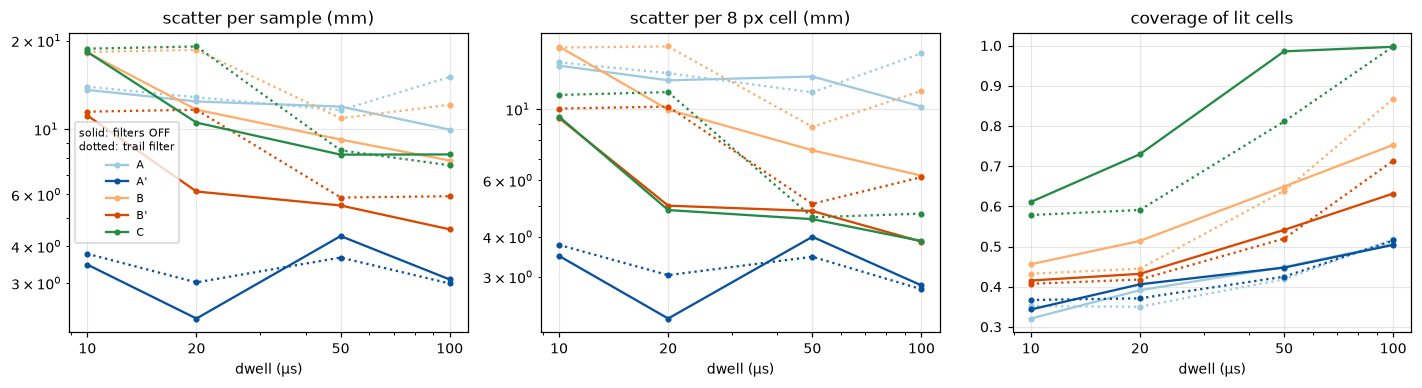

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
for k, (key, label) in enumerate((("mad_mm", "scatter per sample (mm)"), ("cell_mad_mm", "scatter per 8 px cell (mm)"),
                                  ("coverage", "coverage of lit cells"))):
    ax = axs[k]
    for m in METHODS:
        for f, ls in ((OFF, "-"), (TRAIL, ":")):
            ax.plot(ss.DWELLS, [results[(f, d)]["default"][m][key] for d in ss.DWELLS], ls, marker="o", ms=3,
                    color=M_COLORS[m], label=SHORT[m] if f == OFF else None)
    ax.set_xscale("log"); ax.set_xticks(ss.DWELLS, [str(d) for d in ss.DWELLS]); ax.set_xlabel("dwell (µs)")
    ax.set_title(label)
    if key != "coverage":
        ax.set_yscale("log")
axs[0].legend(fontsize=7, title="solid: filters OFF\ndotted: trail filter", title_fontsize=7)
plt.tight_layout(); plt.show()

### Depth and residual maps (cw 20 µs, filters OFF, one scan)

Median per 4 × 4 px block of one scan (white: no sample). Top: depth. Bottom: distance to the fitted plane.

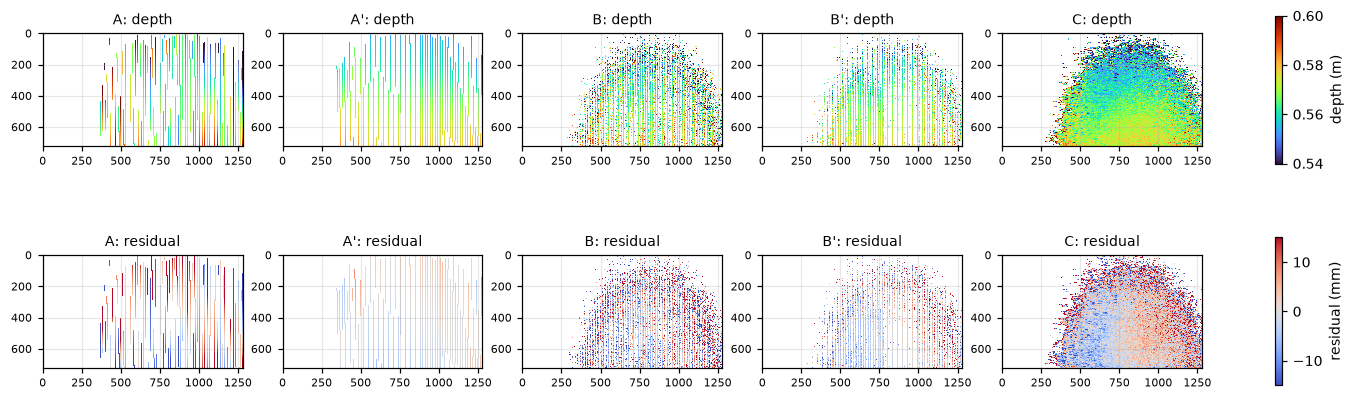

In [9]:
r = results[(OFF, 20)]["default"]
fig, axs = plt.subplots(2, 5, figsize=(17, 4.8))
for j, m in enumerate(METHODS):
    smp = r[m]["samples"][1]
    im0 = axs[0, j].imshow(grid(smp["row"], smp["x"], geom.depth(smp["d"])), cmap="turbo", vmin=0.54, vmax=0.60,
                           extent=(0, 1280, 720, 0), interpolation="nearest")
    im1 = axs[1, j].imshow(grid(smp["row"], smp["x"], smp["resid"]), cmap="coolwarm", vmin=-15, vmax=15,
                           extent=(0, 1280, 720, 0), interpolation="nearest")
    axs[0, j].set_title(f"{SHORT[m]}: depth", fontsize=9)
    axs[1, j].set_title(f"{SHORT[m]}: residual", fontsize=9)
    for i in range(2):
        axs[i, j].tick_params(labelsize=7)
fig.colorbar(im0, ax=axs[0], shrink=0.8, label="depth (m)")
fig.colorbar(im1, ax=axs[1], shrink=0.8, label="residual (mm)")
plt.show()

Plain windows (A, B) give stripes of alternating error: each window's line or median lands at a different point of
the 16 px band in the two cameras. Motion compensation (A′, B′) removes most of it. A′ is the smoothest, because
each line averages ~700 rows. C covers every pixel the stripe crossed, but each value comes from a few events, so
it is noisier per block.

The residual of this single scan also tilts from left to right (clearest for C and B′). Section 6 shows this
for all methods: the plane measured by a right-going scan is tilted relative to that of a left-going scan.

Average residual per 8 × 8 px cell over all scans: structure that repeats from scan to scan, from calibration
error, a non-flat target, or method bias.

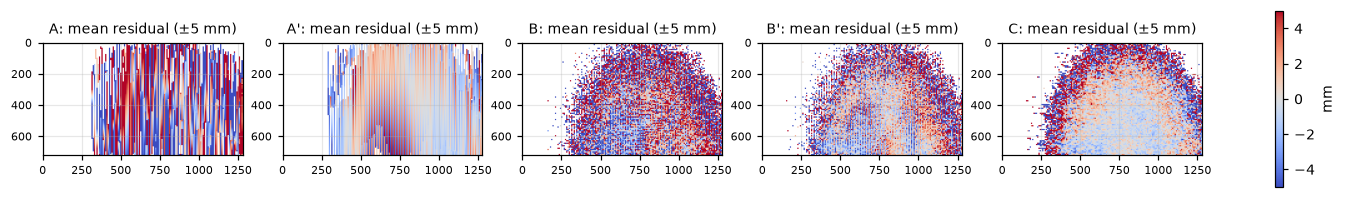

In [10]:
fig, axs = plt.subplots(1, 5, figsize=(17, 2.6))
for j, m in enumerate(METHODS):
    im = axs[j].imshow(r[m]["cell_mean_resid"], cmap="coolwarm", vmin=-5, vmax=5, extent=(0, 1280, 720, 0))
    axs[j].set_title(f"{SHORT[m]}: mean residual (±5 mm)", fontsize=9); axs[j].tick_params(labelsize=7)
plt.colorbar(im, ax=axs, shrink=0.8, label="mm")
plt.show()

The dense methods (B′, C) show a roughly radial pattern of about ±3 mm: farther at the edge of the lit area,
nearer in the centre. Possible causes are residual lens-distortion error (the lenses have strong distortion,
k1 ≈ −0.47) or a latency that depends on brightness, which falls off from the centre of the laser fan. A′ instead
shows vertical bands, one per window.

## 5. Window length and fit width

Parameter sweep on cw 20 µs and cw 50 µs (filters OFF): window length for A/A′/B/B′, fit half-width τ for C, both
in px of stripe motion.

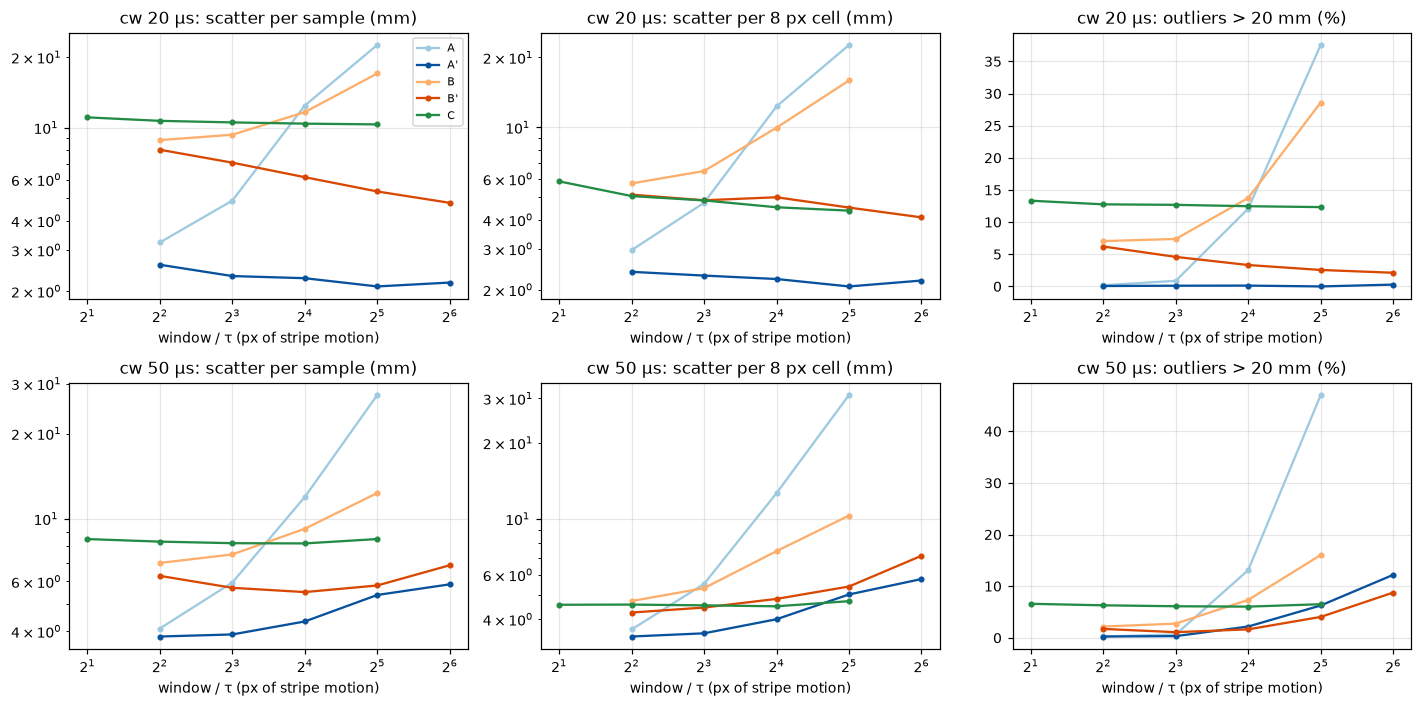

| Dwell (µs) | Method | Best window / τ (by cell scatter) | Scatter/sample (mm) | Scatter per cell (mm) | Coverage | Outliers |
|---|---|---|---|---|---|---|
| 20 | A | 4 px = 105 µs | 3.2 | 3.0 | 76 % | 0.2 % |
| 20 | A' | 32 px = 843 µs | 2.1 | 2.1 | 21 % | 0.0 % |
| 20 | B | 4 px = 105 µs | 8.8 | 5.7 | 57 % | 7.1 % |
| 20 | B' | 64 px = 1686 µs | 4.8 | 4.1 | 12 % | 2.1 % |
| 20 | C | 32 px = 843 µs | 10.3 | 4.4 | 79 % | 12.3 % |
| 50 | A | 4 px = 292 µs | 4.1 | 3.6 | 99 % | 0.3 % |
| 50 | A' | 4 px = 292 µs | 3.8 | 3.4 | 99 % | 0.3 % |
| 50 | B | 4 px = 292 µs | 7.0 | 4.7 | 96 % | 2.2 % |
| 50 | B' | 4 px = 292 µs | 6.3 | 4.2 | 96 % | 1.7 % |
| 50 | C | 16 px = 1170 µs | 8.2 | 4.5 | 99 % | 6.0 % |

In [11]:
SWEEP = {METHODS[0]: [4, 8, 16, 32], METHODS[1]: [4, 8, 16, 32, 64], METHODS[2]: [4, 8, 16, 32],
         METHODS[3]: [4, 8, 16, 32, 64], METHODS[4]: [2, 4, 8, 16, 32]}
sweeps = {d: ss.parameter_sweep(OFF, d, geom, SWEEP, use_cache=USE_CACHE) for d in (20, 50)}
fig, axs = plt.subplots(2, 3, figsize=(13, 6.5))
for i, d in enumerate((20, 50)):
    for m in METHODS:
        res = sweeps[d][m]
        x = [e["param_px"] for e in res]
        axs[i, 0].plot(x, [e["mad_mm"] for e in res], "o-", ms=3, color=M_COLORS[m], label=SHORT[m])
        axs[i, 1].plot(x, [e["cell_mad_mm"] for e in res], "o-", ms=3, color=M_COLORS[m])
        axs[i, 2].plot(x, [e["outliers"] * 100 for e in res], "o-", ms=3, color=M_COLORS[m])
    for k, t in enumerate(("scatter per sample (mm)", "scatter per 8 px cell (mm)", "outliers > 20 mm (%)")):
        axs[i, k].set_xscale("log", base=2); axs[i, k].set_title(f"cw {d} µs: {t}")
        axs[i, k].set_xlabel("window / τ (px of stripe motion)")
        if k < 2:
            axs[i, k].set_yscale("log")
axs[0, 0].legend(fontsize=7)
plt.tight_layout(); plt.show()
rows = []
for d in (20, 50):
    for m in METHODS:
        best = min(sweeps[d][m], key=lambda e: e["cell_mad_mm"])
        rows.append([d, SHORT[m], f"{best['param_px']} px = {best['param_us']:.0f} µs", f"{best['mad_mm']:.1f}",
                     f"{best['cell_mad_mm']:.1f}", f"{best['coverage'] * 100:.0f} %", f"{best['outliers'] * 100:.1f} %"])
md_table(["Dwell (µs)", "Method", "Best window / τ (by cell scatter)", "Scatter/sample (mm)",
          "Scatter per cell (mm)", "Coverage", "Outliers"], rows)

* **Plain windows (A, B) degrade quickly with window length**, because the stripe smears across the window. With a
  **4 px window** (~100 µs at 20 µs dwell, ~300 µs at 50 µs), plain Hough (A) is almost as good as A′: 3.0–3.6 mm
  per cell and < 0.5 % outliers. It also covers 76–99 % of the lit cells, because the lines are only 4 px apart. So
  the original grouping-by-time idea works without motion compensation, as long as the window is short: the stripe
  should move by no more than ~4 px within one window.
* **Motion compensation makes the window length uncritical.** A′ and B′ stay good up to 16–32 px windows, so fewer,
  longer windows can be used, at the cost of sparser lines.
* **C hardly depends on τ** (2–32 px). Its per-sample scatter (~8–10 mm) is set by the per-event floor of section 3.

## 6. Bias between the two scan directions

Plane offset of every scan (median signed distance to the method's plane), coloured by scan direction. A constant
timing offset between the cameras, or a different stripe-edge response in the two cameras, shifts the disparity by
opposite amounts in the two directions.

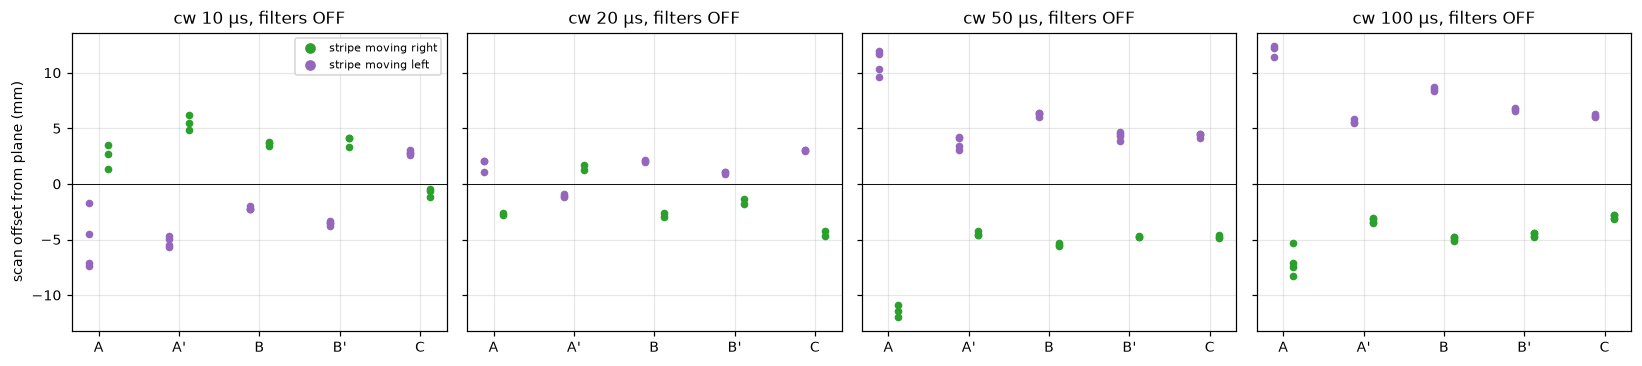

In [12]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for j, d in enumerate(ss.DWELLS):
    ax = axs[j]
    for k, m in enumerate(METHODS):
        for s_ in results[(OFF, d)]["default"][m]["per_scan"]:
            ax.plot(k + (0.12 if s_["direction"] > 0 else -0.12), s_["offset_mm"], "o", ms=4,
                    color="tab:green" if s_["direction"] > 0 else "tab:purple")
    ax.axhline(0, color="k", lw=0.6)
    ax.set_xticks(range(len(METHODS)), [SHORT[m] for m in METHODS]); ax.set_title(f"cw {d} µs, filters OFF")
axs[0].set_ylabel("scan offset from plane (mm)")
axs[0].plot([], [], "o", color="tab:green", label="stripe moving right"); axs[0].plot([], [], "o", color="tab:purple", label="stripe moving left")
axs[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

The offsets split cleanly by direction and repeat from scan to scan, so this is a systematic effect, not noise.

* At **50 and 100 µs dwell**, all motion-compensated methods agree: about **±4.5 mm, i.e. ±1.2 px**, with the left-moving
  scans farther away. In time units, 1.2 px is ~90 µs at 50 µs dwell and ~140 µs at 100 µs, so it is **not a fixed
  clock offset** between the cameras. It is constant in pixels, like the per-event scatter of section 3. This points
  to the two cameras placing the stripe's leading edge ~1 px apart (different sensitivity, focus or stripe
  brightness at the two viewing angles).
* At **10 and 20 µs dwell**, the bias is smaller (0.3–1.4 px), and its sign depends on the estimator (Hough mode,
  median, local mean). There the skewed shape of the edge distribution matters more than its position.

The bias is **not only an offset**. At 20–100 µs dwell, the residual of a single scan also tilts across the image
by ~6–10 mm per 1000 px of x, in every method, with opposite signs for the two directions (table below). At 10 µs
the tilt varies between methods, and the data are too sparse to be conclusive. So the error grows or
shrinks along the scan. That is consistent with an edge offset that varies with stripe brightness or with the
angle of incidence across the scene.

Consequences: (1) a depth frame made of a single scan has a direction-dependent error of up to ~1–2 px (≈ 4–8 mm at
0.57 m, more at larger distances, since the error in depth grows with Z²); (2) it is stable from scan to scan, so it
can be calibrated once on a flat target as a per-direction disparity correction that varies across the image
(e.g. linear in x), or removed by averaging a left-going and a right-going scan.

In [13]:
rows = []
for d in ss.DWELLS:
    res = results[(OFF, d)]["default"]
    dirn = results[(OFF, d)]["summary"]["directions"][1]
    cells = []
    for m in METHODS:
        smp = res[m]["samples"][1]
        k = np.abs(smp["resid"]) < 20
        cells.append(f"{np.polyfit(smp['x'][k], smp['resid'][k], 1)[0] * 1000:+.1f}")
    rows.append([d, "right" if dirn > 0 else "left"] + cells)
md_table(["Dwell (µs)", "Scan direction (scan #1)"] + [f"{SHORT[m]}: tilt (mm / 1000 px)" for m in METHODS], rows)

| Dwell (µs) | Scan direction (scan #1) | A: tilt (mm / 1000 px) | A': tilt (mm / 1000 px) | B: tilt (mm / 1000 px) | B': tilt (mm / 1000 px) | C: tilt (mm / 1000 px) |
|---|---|---|---|---|---|---|
| 10 | right | -8.1 | -23.9 | -3.9 | -5.9 | -0.6 |
| 20 | right | +5.9 | +2.3 | +8.2 | +9.3 | +7.2 |
| 50 | right | +10.7 | +10.6 | +6.2 | +8.7 | +8.2 |
| 100 | left | -6.0 | -8.5 | -9.9 | -9.2 | -9.8 |

## 7. Effect of the neighbour filter

Same evaluation without the neighbour filter (first ON event of each pixel as is).

In [14]:
abl = {d: ss.filter_ablation(OFF, d, geom, use_cache=USE_CACHE) for d in (20, 100)}
rows = []
for d in (20, 100):
    for m in METHODS:
        a, b = abl[d][m], results[(OFF, d)]["default"][m]
        rows.append([d, SHORT[m], f"{a['mad_mm']:.1f} → {b['mad_mm']:.1f}", f"{a['cell_mad_mm']:.1f} → {b['cell_mad_mm']:.1f}",
                     f"{a['outliers'] * 100:.1f} → {b['outliers'] * 100:.1f} %", f"{a['coverage'] * 100:.0f} → {b['coverage'] * 100:.0f} %"])
md_table(["Dwell (µs)", "Method", "Scatter/sample (mm): no filter → filter", "Scatter per cell (mm)", "Outliers",
          "Coverage"], rows)

| Dwell (µs) | Method | Scatter/sample (mm): no filter → filter | Scatter per cell (mm) | Outliers | Coverage |
|---|---|---|---|---|---|
| 20 | A | 12.0 → 12.4 | 11.6 → 12.3 | 12.8 → 12.1 % | 42 → 39 % |
| 20 | A' | 2.4 → 2.3 | 2.4 → 2.2 | 0.4 → 0.1 % | 44 → 41 % |
| 20 | B | 20.2 → 11.6 | 19.2 → 10.0 | 37.1 → 13.8 % | 68 → 51 % |
| 20 | B' | 12.4 → 6.1 | 13.9 → 5.0 | 28.9 → 3.3 % | 61 → 43 % |
| 20 | C | 74.2 → 10.5 | 78.3 → 4.8 | 78.8 → 12.7 % | 88 → 73 % |
| 100 | A | 17.7 → 10.0 | 14.4 → 10.2 | 36.0 → 9.3 % | 51 → 51 % |
| 100 | A' | 5.3 → 3.1 | 4.0 → 2.8 | 15.6 → 0.9 % | 50 → 50 % |
| 100 | B | 25.3 → 7.8 | 28.8 → 6.2 | 46.5 → 3.8 % | 88 → 75 % |
| 100 | B' | 23.6 → 4.6 | 34.2 → 3.9 | 46.8 → 0.6 % | 84 → 63 % |
| 100 | C | 50.7 → 8.2 | 30.2 → 3.9 | 61.7 → 7.5 % | 100 → 100 % |

The filter matters most for the methods that use individual events. Without it, C is unusable: 62–79 % of its
samples are outliers, because a pixel's first event is often noise rather than the stripe. B and B′ improve by a
factor of 2–9. The Hough methods are already robust to scattered events, because the vote ignores them. They
still gain at 100 µs, where scans are long and noise accumulates. The filter costs some coverage at the dim edges
of the lit area.

## 8. Non-flat scenes: synthetic object

The real target is flat, which flatters method A: on a flat surface the stripe *is* a straight line. To test
curved and broken stripes, the right camera's events of cw 20 µs are shifted by a known disparity Δ(y, x),
as if part of the surface were closer (timing unchanged, left camera untouched):

* **box**: Δ = 15 px (≈ 5 cm closer) inside rows 250–450, x 450–850: depth steps, a broken stripe;
* **ridge**: Δ = 15 px · exp(−((y − 360)/100)²) for all x: a smooth horizontal bulge. The right camera's stripe is
  then curved within every window.

Error = measured disparity − (plane + Δ). Per scan, the errors are reduced to their median per 8 × 8 px cell. A
cell is *bad* if that median is off by more than 3 px (≈ 11 mm). Only the right image is modified, so this tests
the correspondence step, not the full optics of a real object.

| Object | Method | Median abs. error per sample (px) | Same, on the object (px) | Bad cells, background | Bad cells, on the object |
|---|---|---|---|---|---|
| box | A | 2.71 | 4.07 | 43 % | 61 % |
| box | A' | 0.64 | 15.19 | 0 % | 99 % |
| box | B | 2.20 | 2.19 | 33 % | 24 % |
| box | B' | 1.16 | 1.15 | 14 % | 7 % |
| box | C | 2.09 | 2.34 | 14 % | 11 % |
| ridge | A | 3.71 | 4.03 | 57 % | 64 % |
| ridge | A' | 2.37 | 8.95 | 28 % | 97 % |
| ridge | B | 2.18 | 2.15 | 32 % | 29 % |
| ridge | B' | 1.14 | 1.14 | 13 % | 13 % |
| ridge | C | 2.05 | 2.17 | 13 % | 10 % |

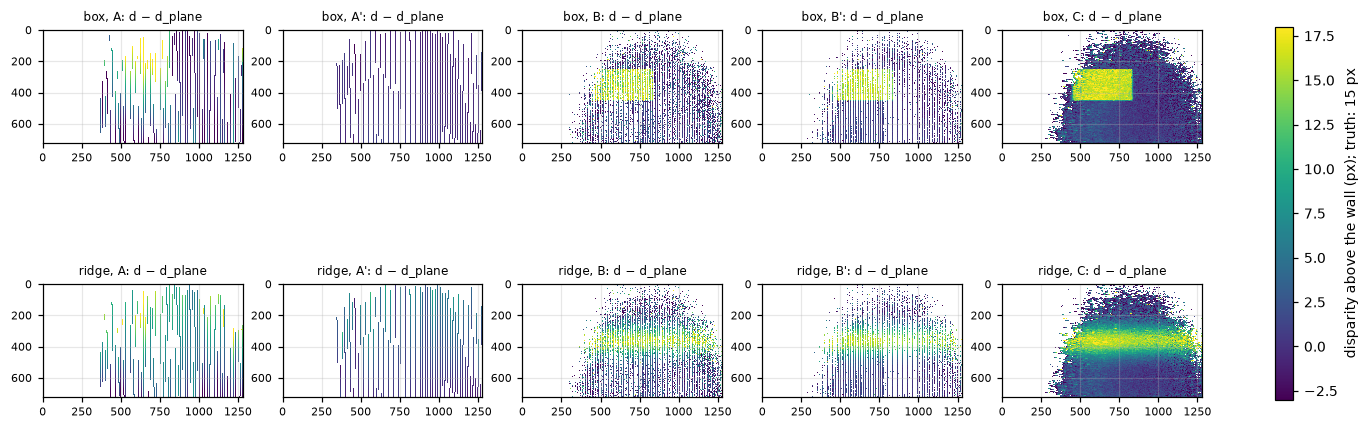

In [15]:
syn = ss.synthetic_test(OFF, 20, geom, use_cache=USE_CACHE)
rows = []
for shape, res in syn["results"].items():
    for m in METHODS:
        e = res[m]
        rows.append([shape, SHORT[m], f"{e['mae_px']:.2f}", f"{e['mae_obj_px']:.2f}", f"{e['bad_cells_bg'] * 100:.0f} %",
                     f"{e['bad_cells_obj'] * 100:.0f} %"])
md_table(["Object", "Method", "Median abs. error per sample (px)", "Same, on the object (px)",
          "Bad cells, background", "Bad cells, on the object"], rows)
fig, axs = plt.subplots(2, 5, figsize=(17, 5.5))
for i, shape in enumerate(("box", "ridge")):
    for j, m in enumerate(METHODS):
        smp = syn["results"][shape][m]["samples"]
        im = axs[i, j].imshow(grid(smp["row"], smp["x"], smp["d_rel"]), cmap="viridis", vmin=-3, vmax=18,
                              extent=(0, 1280, 720, 0), interpolation="nearest")
        axs[i, j].tick_params(labelsize=7)
        axs[i, j].set_title(f"{shape}, {SHORT[m]}: d − d_plane", fontsize=8)
fig.colorbar(im, ax=axs, shrink=0.8, label="disparity above the wall (px); truth: 15 px")
plt.show()

**A′ does not see the object at all.** One straight line per window cannot follow a broken or curved stripe. The
line follows the majority (the wall), and every row of the object gets the wall's disparity: 97–99 % of the
object's cells are wrong by the full 15 px. Plain A is wrong everywhere, because its long windows already fail on
the flat wall. **B′ and C recover the box and the ridge as well as they measure the wall**: the share of bad cells
on the object is no higher than on the background. Their background bad-cell rate (13–14 %) is the noisy edge of
the lit area and the per-event scatter.

## 9. Conclusions

**Target and limits.** The scene is a flat surface at ~0.57 m (disparity ~150 px, 1 px ≈ 3.8 mm). Without ground
truth, these numbers measure precision and robustness, not absolute accuracy.

1. **Time grouping + row matching works.** With the hardware sync, the two cameras' stripes line up in time to
   within ~1 px. With rectification, the match is a 1-D problem per row. Every method finds the correct disparity
   (~150 px) on all 8 recordings.
2. **The time window must be short, or motion-compensated.** In a 16 px window the stripe smears into a band, and
   plain grouping (A, B) gives 10–19 mm scatter and 9–30 % outliers. Two fixes work equally well:
   * windows in which the stripe moves ≤ ~4 px (~100 µs at 20 µs dwell, ~300 µs at 50 µs);
   * moving each event to the window centre with the scan speed (A′, B′).

   Either brings the scatter down to 2–4 mm (0.6–1 px) per sample.
3. **Hough (one straight line per window) is the most precise on a flat surface, and fails on anything else.**
   It averages hundreds of rows: 2.2–4.3 mm per sample, < 1 % outliers. But on a synthetic box or ridge it misses
   97–99 % of the object. Use it only for flat targets (e.g. calibrating the direction bias), or make it local
   (short segments along the stripe).
4. **A single event places the stripe to only ~2–3 px** (~5 px at 10 µs dwell). That is ±8–10 mm in depth, so
   precision has to come from combining events. The scatter is constant in pixels, not in time: it is the width
   of the stripe's leading edge, not clock jitter.
5. **Per-event time matching (C) is the most general and the densest method.** It gives depth wherever the stripe
   passed: 60–100 % of the lit cells, against 35–50 % for the 16 px-window methods. It handles depth steps and
   curves as well as the flat wall, runs as a stream, and needs no line model. It must be combined with spatial
   aggregation: 4–5 mm per 8 × 8 px cell at ≥ 20 µs dwell, against ~8–10 mm per single sample.
   Row-median with motion compensation (B′) is a cheaper alternative with similar robustness and slightly lower
   density.
6. **The neighbour filter is essential.** Without it, the first event of a pixel is often noise (background
   activity, scattered light) rather than the stripe, and C has 62–79 % outliers. With it, C has 6–13 %.
7. **Scans in opposite directions disagree** by an offset of up to ~1.2 px (±4.5 mm here), plus a tilt of
   ~6–10 mm per 1000 px across the image (20–100 µs dwell), in every method. It is not a fixed clock offset between the cameras: it is
   constant in pixels, not in time. It is stable from scan to scan, so a per-direction correction calibrated once
   on a flat target (offset + gradient in x), or pairing opposite scans, removes it. A radial residual pattern of
   ±3 mm also remains, possibly from lens distortion or brightness-dependent latency.
8. **Dwell for ≥ 10 fps:**
   * **20 µs** is the best trade-off here: 34 ms per scan (30 fps one-way), 2.2 mm (A′) and 4.8 mm per cell (C).
   * **50 µs** gives the most complete maps, but needs 94 ms per scan, just 10 fps.
   * **10 µs** is too sparse: the right camera keeps only ~50 k events per scan, and C has 30 % outliers.
9. **The trail filter brings no benefit** for this task. It thins the events, and the left camera's stream gaps
   reappear. Filters OFF, plus masking the two hot pixels and the software neighbour filter, is the better
   configuration.

**Suggested next steps**
* Build the depth pipeline on C (or B′) with the neighbour filter. Add an aggregation step: a median per small cell
  or a short local line fit along the stripe, which combines A′'s precision with locality.
* Calibrate the per-direction offset on a flat target.
* Record a scene with known non-flat geometry (a box in front of a wall at a measured distance) to check absolute
  accuracy and the synthetic results on real data.